# **Экспорт растровых данных и применение методов машинного обучения в среде Google Earth Engine**

## **Введение**

В данном блокноте мы освоим современные методы геопространственного анализа с использованием облачной платформы Google Earth Engine (GEE) и алгоритмов машинного обучения.

**Основные задачи:**
- Научиться работать с облачными каталогами спутниковых данных
- Освоить методы предварительной обработки растровых изображений
- Изучить процесс подготовки данных для алгоритмов машинного обучения
- Применить различные алгоритмы классификации для анализа земного покрова
- Научиться экспортировать и визуализировать результаты анализа

### **Основные определения**

**Геопространственный анализ** — это совокупность методов изучения объектов и явлений с учетом их пространственного расположения. В контексте данного блокнота мы сосредоточимся на следующих ключевых концепциях:

1. **Дистанционное зондирование Земли (ДЗЗ)** — получение информации о земной поверхности без непосредственного контакта, используя спутниковые системы

2. **Спектральный анализ** — изучение отражательной способности объектов в различных участках электромагнитного спектра

3. **Классификация земного покрова** — процесс автоматического распознавания типов земной поверхности по спутниковым снимкам

4. **Облачные вычисления в геоанализе** — использование распределенных вычислительных ресурсов для обработки больших объемов геопространственных данных

---

## **Раздел 1. Основы работы с Google Earth Engine**

### **1.1. Краткая теория**

**Google Earth Engine (GEE)** представляет собой облачную платформу для геопространственного анализа, которая объединяет:
- Петабайтный каталог спутниковых изображений и геопространственных наборов данных
- Вычислительные мощности Google для параллельной обработки данных
- API для доступа и анализа данных через JavaScript и Python

**Преимущества GEE:**
- **Масштабируемость**: обработка происходит на серверах Google, что позволяет анализировать терабайты данных без загрузки на локальный компьютер
- **Доступность данных**: более 1000 публичных наборов данных, включая архивы Landsat, Sentinel, MODIS
- **Скорость обработки**: параллельные вычисления значительно ускоряют анализ больших территорий

**Основные типы данных в GEE:**
- `ee.Image` — растровое изображение (один временной срез)
- `ee.ImageCollection` — коллекция изображений (временная серия)
- `ee.Geometry` — векторная геометрия (точки, линии, полигоны)
- `ee.Feature` — геометрия с атрибутами
- `ee.FeatureCollection` — коллекция объектов

### **1.2. Настройка рабочей среды**

Начнем с установки необходимых библиотек и настройки подключения к Google Earth Engine:

In [ ]:
# Установка необходимых зависимостей
# Команда выполняется в терминале или ячейке Jupyter с префиксом !
# %%capture подавляет вывод установки для чистоты вывода
%%capture
!pip install -U geemap geedim rasterio scikit-learn scikit-image folium

In [ ]:
# Импорт основных библиотек для работы
import ee                        # Основная библиотека Google Earth Engine
import geemap                    # Интерактивные карты для GEE
import numpy as np               # Работа с массивами
import pandas as pd              # Работа с табличными данными
import rasterio                  # Чтение экспортированных GeoTIFF
import matplotlib.pyplot as plt  # Построение графиков

**Пояснение используемых библиотек:**
- `ee` (earthengine-api) — официальный Python API для Google Earth Engine
- `geemap` — расширение для создания интерактивных карт и упрощения работы с GEE
- `numpy` и `pandas` — стандартные библиотеки для научных вычислений
- `geedim` — утилита для загрузки изображений из GEE
- `rasterio` — библиотека для работы с геопривязанными растрами
- `scikit-learn` и `scikit-image` — библиотеки машинного обучения и обработки изображений

### **1.3. Аутентификация и инициализация**

Перед началом работы с geemap и Google Earth Engine необходимо:

- **Зарегистрировать аккаунт Google Earth Engine**: Перейдите на [https://code.earthengine.google.com/register](https://code.earthengine.google.com/register) для создания аккаунта GEE. После регистрации нужно настроить проект Google Cloud и активировать API Earth Engine, следуя инструкциям [здесь](https://docs.google.com/document/d/1ZGSmrNm6_baqd8CHt33kIBWOlvkh-HLr46bODgJN1h0/edit?usp=sharing). GEE бесплатен для [некоммерческого и исследовательского использования](https://earthengine.google.com/noncommercial).

- **Проверить аутентификацию API**: Чтобы убедиться в правильности настройки аккаунта Earth Engine, запустите [этот тестовый блокнот](https://colab.research.google.com/github/gee-community/geemap/blob/master/docs/notebooks/geemap_colab.ipynb) в Google Colab.

In [ ]:
# Аутентификация в Google Earth Engine
# При первом запуске откроется браузер для авторизации через Google аккаунт
ee.Authenticate()

# Инициализация Earth Engine с указанием проекта
# Важно: замените 'seraphic-effect-413810' на имя вашего проекта в Google Cloud
ee.Initialize(project='seraphic-effect-413810')

**Важные моменты:**
- Аутентификация требуется только при первом подключении
- Для работы необходим Google Cloud Project с активированным Earth Engine API
- Бесплатный доступ предоставляется для исследовательских и образовательных целей

### **1.4. Создание интерактивной карты и определение области интереса**

In [ ]:
# Создание интерактивной карты с центром на Москве
# center - координаты центра карты [широта, долгота]
# zoom - уровень приближения (1-20)
Map = geemap.Map(center=[55.7558, 37.6173], zoom=10)
Map.add_basemap('Esri.WorldTopoMap')

# Добавление инструментов рисования для выделения области интереса
Map.add_draw_control()

# Отображение карты в Jupyter notebook
Map

Map(center=[55.7558, 37.6173], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topri…

**Функционал интерактивной карты:**
- Инструменты рисования позволяют выделить полигон, прямоугольник или точку
- Выбранная область автоматически сохраняется как `Map.user_roi`
- Базовые слои карты можно переключать в правом верхнем углу
- Если область не нарисована, используется участок по умолчанию — около 14×13 км у Клязьминского водохранилища, где есть вода, лес, застройка и поля

In [ ]:
# Функция для получения области интереса (Area of Interest - AOI)
def get_user_roi():
    """
    Извлекает пользовательскую область интереса из интерактивной карты.
    Если область не нарисована, возвращает участок по умолчанию.

    Возвращает:
        ee.Geometry: объект геометрии для использования в анализе
    """
    if Map.user_roi is not None:
        # Возвращаем нарисованную пользователем область
        return Map.user_roi
    else:
        # Участок по умолчанию: Клязьминское водохранилище и окрестности (около 14×13 км)
        # Координаты задаются как [западная долгота, южная широта, восточная долгота, северная широта]
        return ee.Geometry.Rectangle([37.40, 55.92, 37.62, 56.04])

# Получение и визуализация области интереса
roi = get_user_roi()

# Центрирование карты на выбранной области
map_roi = geemap.Map(zoom=10)
map_roi.add_basemap('Esri.WorldTopoMap')

map_roi.centerObject(roi, 11)

# Добавление слоя с границами области
# color - цвет границы, name - название слоя в легенде
map_roi.addLayer(roi, {'color': 'red'}, 'Область интереса')

# Повторное отображение карты с добавленными слоями
map_roi

Map(center=[55.98001793820693, 37.51000000000046], controls=(WidgetControl(options=['position', 'transparent_b…

### **Выводы по разделу 1:**

1. **Google Earth Engine** предоставляет эффективный инструментарий для работы с геопространственными данными без необходимости их локальной загрузки
2. **Интерактивные карты** упрощают выбор области исследования и визуализацию результатов
3. **Правильное определение области интереса** важно для оптимизации вычислений и получения релевантных результатов

---

## **Раздел 2. Загрузка и предварительная обработка спутниковых данных**

### **2.1. Краткая теория**

**Системы дистанционного зондирования Земли** регулярно получают изображения земной поверхности в различных участках электромагнитного спектра.


Каждая система имеет свои характеристики:

**Sentinel-2** (Европейское космическое агентство):
- Пространственное разрешение: 10-60 м в зависимости от канала
- Временное разрешение: 5 дней (с двумя спутниками)
- Спектральные каналы: 13 диапазонов от видимого до коротковолнового инфракрасного

**Доступность данных уровня 2A.** Коллекция `COPERNICUS/S2_SR_HARMONIZED` (уровень 2A, с атмосферной коррекцией) покрывает весь мир с конца 2018 года. За 2017–2018 годы снимков уровня 2A для многих районов почти нет: например, для участка по умолчанию за лето 2017 года их 3, тогда как снимков уровня 1C (`COPERNICUS/S2_HARMONIZED`, без атмосферной коррекции) — 117. Поэтому временные ряды по снимкам уровня 2A надёжно строятся начиная с 2019 года.

**Основные спектральные каналы Sentinel-2:**
- B2 (490 нм) — синий, для изучения водных объектов
- B3 (560 нм) — зеленый, пик отражения растительности
- B4 (665 нм) — красный, поглощение хлорофиллом
- B8 (842 нм) — ближний инфракрасный, высокое отражение растительности
- B11 (1610 нм) и B12 (2190 нм) — коротковолновые инфракрасные, чувствительны к влажности почвы и растительности, используются в индексах застройки и воды

**Предварительная обработка** включает:
- Фильтрацию по облачности
- Маскирование облаков и теней
- Атмосферную коррекцию (в продуктах уровня 2A)
- Создание безоблачных композитов

### **2.2. Загрузка и фильтрация коллекции снимков**

In [ ]:
def load_sentinel2_collection(roi, start_date, end_date, cloud_percentage=20):
    """
    Загружает и фильтрует коллекцию снимков Sentinel-2 Surface Reflectance.

    Параметры:
        roi (ee.Geometry): область интереса для пространственной фильтрации
        start_date (str): начальная дата в формате 'YYYY-MM-DD'
        end_date (str): конечная дата в формате 'YYYY-MM-DD'
        cloud_percentage (int): максимальный процент облачности (0-100)

    Возвращает:
        ee.ImageCollection: отфильтрованная коллекция с масками облаков
    """

    # Загрузка коллекции Sentinel-2 Level-2A (с атмосферной коррекцией)
    # HARMONIZED версия обеспечивает согласованность данных между периодами
    collection = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')

    # Последовательное применение фильтров:

    # 1. Пространственный фильтр - только снимки, покрывающие нашу область
    collection = collection.filterBounds(roi)

    # 2. Временной фильтр - снимки за указанный период
    collection = collection.filterDate(start_date, end_date)

    # 3. Фильтр по метаданным - исключаем слишком облачные снимки
    collection = collection.filter(
        ee.Filter.lessThan('CLOUDY_PIXEL_PERCENTAGE', cloud_percentage)
    )

    # Функция для маскирования облаков на уровне пикселей
    def mask_clouds(image):
        """Применяет маску облаков и теней к отдельному изображению"""

        # SCL - карта классификации сцены, построенная при атмосферной коррекции
        scl = image.select('SCL')

        # Исключаемые классы: 3 - тени облаков, 8 и 9 - облака средней и высокой вероятности,
        # 10 - перистые облака
        mask = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10))

        # Применение маски к спектральным каналам и преобразование значений к диапазону 0-1
        # Sentinel-2 хранит значения отражения умноженными на 10000
        return image.select('B.*').updateMask(mask).divide(10000).copyProperties(
            image, ['system:time_start']  # Сохраняем временную метку
        )

    # Применение функции маскирования ко всем снимкам коллекции
    return collection.map(mask_clouds)

**О коллекции Sentinel-2:**
- **COPERNICUS/S2_SR_HARMONIZED** - это коллекция снимков со спутников Sentinel-2 с уже выполненной атмосферной коррекцией (Level-2A), что означает устранение влияния атмосферы на значения отражения. Версия **HARMONIZED** обеспечивает согласованность данных между разными временными периодами (приводит снимки, обработанные разными версиями алгоритма ESA, к единой шкале), что важно для анализа временных рядов

**Фильтрация данных:**
- **Пространственный фильтр** (`filterBounds`) - отбирает только те снимки, которые пересекаются с вашей областью интереса, экономя вычислительные ресурсы
- **Временной фильтр** (`filterDate`) - ограничивает данные указанным периодом
- **Фильтр по облачности** (`CLOUDY_PIXEL_PERCENTAGE`) - исключает снимки с процентом облачности выше заданного порога на уровне всей сцены

**Маскирование облаков:**
- **Канал SCL (Scene Classification Layer)** - карта классов, которую алгоритм атмосферной коррекции строит для каждого пикселя снимка уровня 2A: растительность, вода, почва, облака, тени облаков и другие. Облакам и теням соответствуют классы 3 (тени облаков), 8 и 9 (облака средней и высокой вероятности) и 10 (перистые облака)
- **Операции сравнения** (`neq` - «не равно», `And` - логическое И) проверяют класс каждого пикселя
- **Маска** создает бинарное изображение: 1 - чистые пиксели, 0 - облака и тени, которые будут исключены из анализа функцией `updateMask`

**Канал QA60.** Во многих примерах облака маскируют по каналу качества **QA60**, где биты 10 и 11 отвечают за обычные и перистые облака соответственно, а битовые операции (`bitwiseAnd`) проверяют состояние этих битов для каждого пикселя. Однако в снимках, обработанных ESA с начала 2022 года, этот канал не заполняется: например, для всех летних снимков 2023 года над участком по умолчанию маска QA60 пустая, хотя облачность на них доходит до 40-80%. Поэтому для снимков уровня 2A маска строится по каналу SCL.

**Нормализация значений:**
- **Деление на 10000** необходимо, так как Sentinel-2 хранит значения отражения умноженными на 10000 для экономии места (целые числа занимают меньше памяти, чем дробные). После деления получаем физически корректные значения коэффициента отражения в диапазоне 0-1, и формулы индексов (например, EVI) дают правильные результаты
- Делятся только спектральные каналы (`B.*`): служебные каналы (SCL и другие) в дальнейшем анализе не нужны

**Результат:**
Функция возвращает коллекцию очищенных от облаков снимков с нормализованными значениями, готовую для дальнейшего анализа (расчет индексов, классификация и т.д.).

In [ ]:
# Пример использования функции
start_date = '2023-05-01'    # Начало вегетационного периода
end_date = '2023-09-30'      # Конец вегетационного периода
sentinel_collection = load_sentinel2_collection(roi, start_date, end_date, 5)

# Вывод количества найденных снимков
print(f"Найдено снимков: {sentinel_collection.size().getInfo()}")

Найдено снимков: 29


### **2.3. Создание безоблачных композитов**

In [ ]:
def create_median_composite(collection, roi):
    """
    Создает медианный композит из коллекции изображений.
    Медиана эффективно удаляет облака и выбросы.

    Параметры:
        collection (ee.ImageCollection): коллекция изображений
        roi (ee.Geometry): область для обрезки результата

    Возвращает:
        ee.Image: медианный композит
    """
    # Вычисление медианы для каждого пикселя по всей временной серии
    # Медиана устойчива к выбросам (облакам, теням)
    median_image = collection.median()

    # Обрезка результата по границам области интереса
    # Это уменьшает объем данных для дальнейшей обработки
    median_image = median_image.clip(roi)

    return median_image

**О медианном композите:**
- **Медианный композит** - это изображение, где значение каждого пикселя представляет собой медиану всех значений этого пикселя во временной серии снимков
- В отличие от среднего значения, **медиана устойчива к выбросам** - экстремальные значения (облака, тени, блики) не искажают результат

**Преимущества медианы для спутниковых данных:**
- **Удаление оставшихся облаков**: маска SCL убирает основную часть облаков, а их края и дымка, пропущенные маской, имеют аномально высокие значения отражения и при вычислении медианы исключаются как выбросы
- **Удаление теней**: тени от облаков имеют аномально низкие значения и также отфильтровываются
- **Сохранение типичных значений**: медиана выбирает "средний" пиксель из временного ряда, который с высокой вероятностью представляет безоблачные условия

**Процесс создания композита:**
- Для каждой позиции пикселя берутся все незамаскированные значения из коллекции (например, 10 снимков = до 10 значений)
- Значения сортируются и выбирается центральное (медианное) значение
- Результат - одно "чистое" изображение без облаков и артефактов

**Результат:**
Функция возвращает единое безоблачное изображение, представляющее типичные условия поверхности за весь анализируемый период - идеально для анализа землепользования, классификации и мониторинга изменений.

In [ ]:
# Создание медианного композита
median_composite = create_median_composite(sentinel_collection, roi)

# Параметры визуализации для естественных цветов (RGB)
vis_params = {
    'bands': ['B4', 'B3', 'B2'],  # Красный, зеленый, синий каналы
    'min': 0.0,                     # Минимальное значение отражения
    'max': 0.3,                     # Максимальное значение отражения
    'gamma': 1.4                    # Гамма-коррекция для улучшения контраста
}

# Добавление композита на карту
map_composite = geemap.Map()
map_composite.add_basemap('Esri.WorldTopoMap')
map_composite.centerObject(roi, 11)
map_composite.addLayer(median_composite, vis_params, 'Медианный композит RGB')

# Отображение обновленной карты
map_composite

Map(center=[55.98001793820693, 37.51000000000046], controls=(WidgetControl(options=['position', 'transparent_b…

### **2.4. Экспорт геопривязанных растров**

**Выбор системы координат при экспорте.** Размер пикселя `scale` задаётся в метрах, но фактический размер пикселя зависит от проекции. В географической системе координат EPSG:4326 пиксель задаётся в градусах: при `scale=10` GEE берёт 10 м на экваторе, то есть 0,0000898°. На широте Москвы (около 56°) такой пиксель занимает 10 м с севера на юг, но лишь около 5,6 м с запада на восток. Если потом считать площадь как «число пикселей × 100 м²», она окажется завышенной почти вдвое.

Поэтому растры экспортируются в метрической проекции **UTM** (Universal Transverse Mercator): Земля разбита на 60 зон шириной по 6° долготы, и внутри своей зоны пиксель имеет размер ровно 10×10 м. Номер зоны вычисляется по долготе центра области: зона = ⌊(долгота + 180) / 6⌋ + 1, а код EPSG для северного полушария — 32600 + номер зоны (для южного — 32700 + номер зоны).

Растр загружается плитками размером 256×256 пикселей (параметр `max_tile_dim`): каждая плитка рассчитывается на серверах GEE отдельным небольшим запросом, и плитки загружаются параллельно. Если запросить весь участок одним запросом, ресурсоёмкие вычисления — например, классификация градиентным бустингом, который GEE заново обучает при каждом запросе, — могут не уложиться в ограничение GEE на время одного запроса, и загрузка зависнет.

In [ ]:
def utm_crs(roi):
    """
    Возвращает код EPSG зоны UTM, в которую попадает центр области интереса.
    """
    lon, lat = roi.centroid(maxError=1).coordinates().getInfo()
    zone = int((lon + 180) // 6) + 1
    return f'EPSG:{(32600 if lat >= 0 else 32700) + zone}'


def export_georeferenced_raster(image, roi, filename, scale=10, dtype='float32', tile_size=256):
    """
    Экспортирует изображение Earth Engine в геопривязанный GeoTIFF файл.

    Параметры:
        image (ee.Image): изображение для экспорта
        roi (ee.Geometry): область экспорта
        filename (str): имя выходного файла
        scale (int): размер пикселя в метрах
        dtype (str): тип данных ('float32' для отражения и индексов, 'uint8' для карт классов)
        tile_size (int): размер плиток загрузки в пикселях

    Возвращает:
        str: путь к сохраненному файлу
    """
    crs = utm_crs(roi)  # Метрическая проекция: пиксель scale×scale метров

    # Использование geemap для загрузки с сохранением геопривязки
    geemap.download_ee_image(
        image=image,
        filename=filename,
        scale=scale,      # Размер пикселя в метрах
        region=roi,       # Границы экспорта
        crs=crs,          # Система координат UTM
        dtype=dtype,      # Тип данных в файле
        max_tile_dim=tile_size  # Загрузка плитками tile_size×tile_size пикселей
    )

    print(f"Растр сохранен: {filename} ({crs}, пиксель {scale}×{scale} м)")
    return filename

In [ ]:
# Экспорт медианного композита (10 спектральных каналов с разрешением 10 и 20 м)
export_bands = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']
export_filename = "sentinel2_median_composite.tif"
export_georeferenced_raster(median_composite.select(export_bands), roi, export_filename, scale=10)

  0%|          |0/360 tiles [00:00<?]

Растр сохранен: sentinel2_median_composite.tif (EPSG:32637, пиксель 10×10 м)


'sentinel2_median_composite.tif'

Откроем сохранённый файл в `rasterio` и проверим систему координат, размер пикселя и содержимое. Площадь одного пикселя в метрической проекции равна произведению его размеров, поэтому площадь любого участка — это число его пикселей, умноженное на эту величину.

Система координат: EPSG:32637
Размер пикселя: 10 × 10 м, площадь пикселя 100 м²
Размер растра: 1402 × 1366 пикселей, каналов: 10


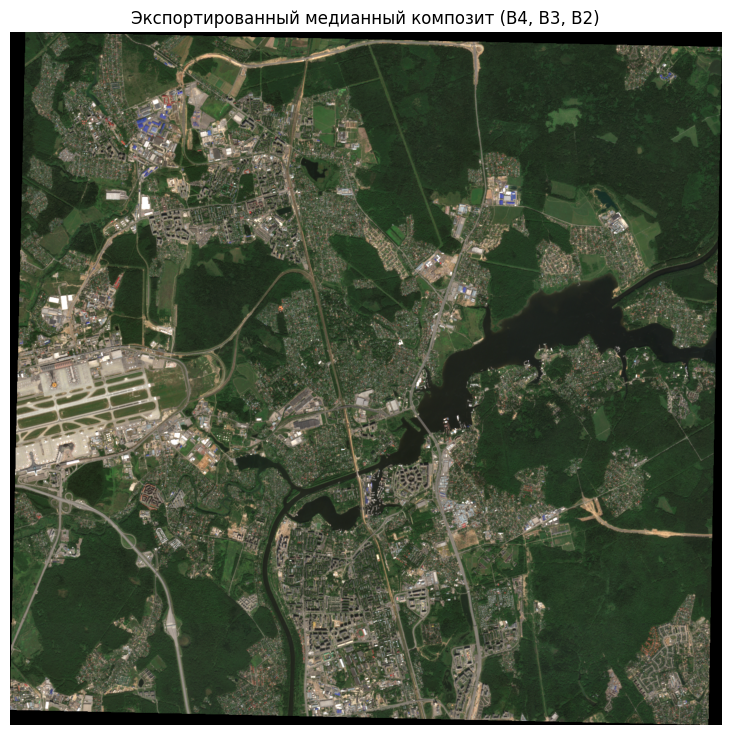

In [ ]:
with rasterio.open(export_filename) as src:
    print(f"Система координат: {src.crs}")
    print(f"Размер пикселя: {src.res[0]:.0f} × {src.res[1]:.0f} м, площадь пикселя {src.res[0] * src.res[1]:.0f} м²")
    print(f"Размер растра: {src.width} × {src.height} пикселей, каналов: {src.count}")
    rgb = src.read([3, 2, 1])  # B4, B3, B2 — красный, зеленый, синий

# Перевод в формат (строки, столбцы, каналы) и растяжение отражения 0-0.3 на яркость 0-1
rgb = np.clip(np.nan_to_num(np.transpose(rgb, (1, 2, 0))) / 0.3, 0, 1) ** (1 / 1.4)

plt.figure(figsize=(10, 9))
plt.imshow(rgb)
plt.title('Экспортированный медианный композит (B4, B3, B2)')
plt.axis('off')
plt.show()

### **Выводы по разделу 2:**

1. **Временные серии спутниковых снимков** позволяют создавать качественные безоблачные композиты даже для регионов с частой облачностью
2. **Медианные композиты** в сочетании с маской облаков по каналу SCL эффективно устраняют различные артефакты (облака, тени) при сохранении спектральных характеристик поверхности
3. **Правильная фильтрация данных** на этапе загрузки существенно сокращает объем обрабатываемой информации
4. **Сохранение геопривязки** особенно важно для последующего использования результатов в ГИС
5. **Экспорт в метрической проекции (UTM)** дает пиксели одинакового размера в метрах, что необходимо для правильного расчета площадей

---

## **Раздел 3. Формирование обучающих выборок для машинного обучения**

### **3.1. Краткая теория**

**Обучение с учителем** в задачах классификации земного покрова требует размеченных данных — примеров пикселей с известными классами. Качество обучающей выборки напрямую влияет на точность классификации.

**Источники эталонных данных:**
1. **Готовые глобальные карты** (ESA WorldCover, MODIS Land Cover)
   - Преимущества: большой охват, проверенное качество
   - Недостатки: возможное несоответствие времени съемки, генерализация

2. **Ручная разметка**
   - Преимущества: точность для конкретной задачи
   - Недостатки: трудоемкость, субъективность

3. **Полевые данные**
   - Преимущества: максимальная достоверность
   - Недостатки: ограниченный объем, высокая стоимость

**Спектральные индексы** — математические комбинации спектральных каналов, подчеркивающие определенные характеристики поверхности:
- **NDVI** (Normalized Difference Vegetation Index) — индикатор растительности
- **NDWI** (Normalized Difference Water Index) — выделение водных объектов
- **NDBI** (Normalized Difference Built-up Index) — городская застройка

### **3.2. Загрузка эталонных данных о земном покрове**

In [ ]:
def load_landcover_data(roi, year=2021):
    """
    Загружает глобальную карту земного покрова ESA WorldCover.

    ESA WorldCover - продукт с разрешением 10м, созданный на основе
    данных Sentinel-1 и Sentinel-2 с использованием машинного обучения.

    Классы земного покрова:
        10 - Древесная растительность (Tree cover)
        20 - Кустарники (Shrubland)
        30 - Травянистая растительность (Grassland)
        40 - Пахотные земли (Cropland)
        50 - Застроенные территории (Built-up)
        60 - Голая почва / редкая растительность (Bare / sparse vegetation)
        70 - Снег и лед (Snow and ice)
        80 - Постоянные водные объекты (Permanent water bodies)
        90 - Травянистые водно-болотные угодья (Herbaceous wetland)
        95 - Мангровые заросли (Mangroves)
        100 - Мхи и лишайники (Moss and lichen)

    Параметры:
        roi (ee.Geometry): область интереса
        year (int): год данных (доступны 2020 и 2021)

    Возвращает:
        ee.Image: карта классификации земного покрова
    """

    # Загрузка коллекции ESA WorldCover
    # v100 - версия 1.0.0 продукта (карта 2020 года), v200 - версия 2.0.0 (карта 2021 года)
    version = {2020: 'v100', 2021: 'v200'}[year]
    landcover = ee.ImageCollection(f"ESA/WorldCover/{version}").first()

    # Выбор канала 'Map' содержащего классификацию
    # и обрезка по области интереса
    landcover = landcover.select('Map').clip(roi)

    return landcover

In [ ]:
# Загрузка карты классификации за 2021 год - ближайший к году композита (2023)
landcover = load_landcover_data(roi, year=2021)

Коды классов WorldCover (10, 20, …, 90, 95, 100) идут неравномерно, поэтому палитру нельзя растянуть по диапазону 10–100: цвет каждого класса определялся бы его положением на шкале, и цвета разошлись бы с классами. Сначала коды переводятся в порядковые номера 0–10 функцией `remap`, а палитра задаётся для номеров: i-й цвет соответствует i-му классу.

In [ ]:
# Коды и названия классов ESA WorldCover
CLASS_CODES = [10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 100]
CLASS_NAMES = ['Деревья', 'Кустарники', 'Травянистая растительность', 'Пахотные земли',
               'Застроенные территории', 'Голая почва', 'Снег и лед', 'Вода',
               'Водно-болотные угодья', 'Мангровые заросли', 'Мхи и лишайники']

# Цвета классов в том же порядке
CLASS_COLORS = [
    '006400',  # 10 - Деревья - темно-зеленый
    '7cfc00',  # 20 - Кустарники - светло-зеленый
    '9acd32',  # 30 - Травянистая растительность - желто-зеленый
    'f0e68c',  # 40 - Пахотные земли - хаки
    'ff0000',  # 50 - Застроенные территории - красный
    'd2691e',  # 60 - Голая почва - коричневый
    'ffffff',  # 70 - Снег и лед - белый
    '1e90ff',  # 80 - Вода - синий
    '00bfff',  # 90 - Водно-болотные угодья - голубой
    '008b8b',  # 95 - Мангровые заросли - темно-бирюзовый
    '98fb98'   # 100 - Мхи и лишайники - бледно-зеленый
]

# Параметры визуализации: порядковые номера классов 0-10
landcover_vis = {'min': 0, 'max': 10, 'palette': CLASS_COLORS}

def to_class_index(image):
    """Переводит коды классов WorldCover в порядковые номера 0-10 для визуализации."""
    return image.remap(CLASS_CODES, list(range(len(CLASS_CODES))))

# Визуализация эталонной карты
map_reference = geemap.Map()
map_reference.add_basemap('Esri.WorldTopoMap')
map_reference.centerObject(roi, 11)
map_reference.addLayer(to_class_index(landcover), landcover_vis, 'Земной покров ESA WorldCover')
map_reference.add_legend(title='ESA WorldCover', legend_dict=dict(zip(CLASS_NAMES, CLASS_COLORS)))
map_reference

Map(center=[55.98001793820693, 37.51000000000046], controls=(WidgetControl(options=['position', 'transparent_b…

In [ ]:
# Экспорт эталонной карты для дальнейшего использования (коды классов - целые числа)
landcover_filename = "esa_worldcover_classification.tif"
export_georeferenced_raster(landcover, roi, landcover_filename, scale=10, dtype='uint8')

2021:   0%|          |0/36 tiles [00:00<?]

Растр сохранен: esa_worldcover_classification.tif (EPSG:32637, пиксель 10×10 м)


'esa_worldcover_classification.tif'

### **3.3. Расчет спектральных индексов**

In [ ]:
def add_spectral_indices(image):
    """
    Добавляет спектральные индексы к мультиспектральному изображению.
    Индексы улучшают разделимость классов земного покрова.

    Параметры:
        image (ee.Image): исходное изображение Sentinel-2

    Возвращает:
        ee.Image: изображение с добавленными индексами
    """

    # NDVI - Нормализованный вегетационный индекс
    # Формула: (NIR - RED) / (NIR + RED)
    # Диапазон: [-1, 1], где высокие значения указывают на здоровую растительность
    ndvi = image.normalizedDifference(['B8', 'B4']).rename('NDVI')

    # NDWI - Нормализованный водный индекс
    # Формула: (GREEN - NIR) / (GREEN + NIR)
    # Положительные значения обычно указывают на водные поверхности
    ndwi = image.normalizedDifference(['B3', 'B8']).rename('NDWI')

    # NDBI - Нормализованный индекс застройки
    # Формула: (SWIR - NIR) / (SWIR + NIR)
    # Высокие значения характерны для городских территорий
    ndbi = image.normalizedDifference(['B11', 'B8']).rename('NDBI')

    # EVI - Улучшенный вегетационный индекс
    # Более сложная формула, учитывающая атмосферные эффекты
    # Менее чувствителен к насыщению при высокой биомассе
    evi = image.expression(
        '2.5 * ((NIR - RED) / (NIR + 6 * RED - 7.5 * BLUE + 1))',
        {
            'NIR': image.select('B8'),    # Ближний инфракрасный
            'RED': image.select('B4'),    # Красный
            'BLUE': image.select('B2')    # Синий
        }
    ).rename('EVI')

    # Добавление всех индексов к исходному изображению
    return image.addBands([ndvi, ndwi, ndbi, evi])

### **3.4. Создание обучающей выборки**

In [ ]:
def create_training_samples(image, landcover, roi, num_points=5000, scale=10):
    """
    Создает обучающую выборку путем случайной выборки точек.

    Процесс включает:
    1. Объединение спектральных данных с эталонными классами
    2. Случайную выборку пикселей в пределах области
    3. Извлечение значений всех каналов для каждой точки

    Параметры:
        image (ee.Image): мультиспектральное изображение с индексами
        landcover (ee.Image): эталонная карта классификации
        roi (ee.Geometry): область выборки
        num_points (int): количество точек для выборки
        scale (int): пространственное разрешение выборки в метрах

    Возвращает:
        ee.FeatureCollection: коллекция точек с атрибутами
    """

    # Объединение спектральных данных и карты классов в одно изображение
    # Переименовываем канал карты классификации для ясности
    combined = image.addBands(landcover.rename('class'))

    # Случайная выборка пикселей
    # seed обеспечивает воспроизводимость результатов
    points = combined.sample(
        region=roi,              # Область выборки
        scale=scale,            # Разрешение (размер пикселя)
        numPixels=num_points,   # Количество точек
        seed=42,                # Фиксированное начальное значение для воспроизводимости
        geometries=True         # Сохранить координаты точек
    )

    return points

In [ ]:
# Добавление индексов к медианному композиту
image_with_indices = add_spectral_indices(median_composite)

# Создание обучающей выборки
training_points = create_training_samples(
    image_with_indices,
    landcover,
    roi,
    num_points=10000,  # Достаточное количество для обучения
    scale=10          # Соответствует разрешению Sentinel-2
)

print(f"Создано обучающих точек: {training_points.size().getInfo()}")

Создано обучающих точек: 10000


Метки WorldCover относятся к 2021 году, а композит — к 2023: там, где покров за два года изменился, метки будут неверны. Такие ошибки в эталоне ограничивают точность любой модели, обученной на нём.

### **Выводы по разделу 3:**

1. **Качественные эталонные данные** — основа успешной классификации. Карты классификации по типу ESA WorldCover обеспечивают хороший баланс между качеством и доступностью
2. **Спектральные индексы** значительно улучшают разделимость классов, особенно для растительности и водных объектов
3. **Размер обучающей выборки** должен быть достаточным для представления вариабельности каждого класса (обычно не менее 100-200 точек на класс)
4. **Пространственное распределение** точек выборки имеет значение — случайная выборка обеспечивает репрезентативность

---

## **Раздел 4. Применение алгоритмов машинного обучения**

### **4.1. Краткая теория**

**Машинное обучение в геопространственном анализе** применяется для автоматической классификации земного покрова, выявления изменений и прогнозирования.

**Основные алгоритмы классификации:**

1. **Random Forest** (Случайный лес)
   - Ансамбль решающих деревьев
   - Устойчив к переобучению
   - Хорошо работает с разнородными признаками

2. **Support Vector Machine** (SVM, Метод опорных векторов)
   - Находит оптимальную разделяющую гиперплоскость
   - Эффективен в пространствах высокой размерности
   - Чувствителен к масштабу признаков

3. **CART** (Classification and Regression Trees)
   - Простое дерево решений
   - Интерпретируемые результаты
   - Склонен к переобучению

4. **Gradient Boosting**
   - Последовательное построение деревьев
   - Высокая точность
   - Требует настройки параметров

**Метрики оценки качества:**
- **Общая точность** (Overall Accuracy) — доля правильно классифицированных пикселей
- **Каппа Коэна** (Kappa) — согласованность с учетом случайного совпадения
- **Матрица ошибок** (Confusion Matrix) — детальный анализ ошибок по классам

### **4.2. Подготовка данных и обучение моделей**

In [ ]:
# Импорт дополнительных библиотек для визуализации
import matplotlib.pyplot as plt
import seaborn as sns

# Определение признаков для обучения
# Включаем все спектральные каналы и рассчитанные индексы
bands = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12',
         'NDVI', 'NDWI', 'NDBI', 'EVI']
label = 'class'  # Целевая переменная

# Разделение данных на обучающую и валидационную выборки
split = 0.7  # 70% для обучения, 30% для валидации

# Добавление случайного столбца для разделения
data = training_points.randomColumn('random', seed=42)

# Разделение по случайному значению
train_data = data.filter(ee.Filter.lt('random', split))
val_data = data.filter(ee.Filter.gte('random', split))

print(f"Размер обучающей выборки: {train_data.size().getInfo()}")
print(f"Размер валидационной выборки: {val_data.size().getInfo()}")

Размер обучающей выборки: 6995
Размер валидационной выборки: 3005


### **4.3. Обучение и сравнение классификаторов**

In [ ]:
# Определение классификаторов с оптимальными параметрами
classifiers = {
    'Random Forest': ee.Classifier.smileRandomForest(
        numberOfTrees=100,    # Количество деревьев в ансамбле
        seed=42              # Для воспроизводимости
    ),
    'CART': ee.Classifier.smileCart(
        maxNodes=None        # Без ограничения глубины
    ),
    'Naive Bayes': ee.Classifier.smileNaiveBayes(),  # Рассчитан на неотрицательные целые признаки (счётчики)
    'SVM': ee.Classifier.libsvm(
        kernelType='RBF',    # Радиальная базисная функция
        gamma=0.1,           # Параметр ядра
        cost=10              # Параметр регуляризации
    ),
    'Gradient Boost': ee.Classifier.smileGradientTreeBoost(
        numberOfTrees=50,    # Количество итераций бустинга
        shrinkage=0.1,       # Скорость обучения
        seed=42
    ),
    'Min Distance': ee.Classifier.minimumDistance(
        metric='euclidean'   # Евклидово расстояние
    )
}

In [ ]:
print("Обучение моделей...")

# Словари для сохранения обученных моделей и результатов
models = {}
results = {}

# Обучение каждого классификатора
for name, clf in classifiers.items():
    # Обучение модели на тренировочных данных
    model = clf.train(
        features=train_data,
        classProperty=label,
        inputProperties=bands
    )

    # Сохранение обученной модели для последующего использования
    models[name] = model

    # Валидация модели
    # Применяем модель к валидационным данным
    validated = val_data.classify(model)

    # Вычисление матрицы ошибок
    error_matrix = validated.errorMatrix(label, 'classification')

    # Сохранение результатов
    results[name] = {
        'accuracy': error_matrix.accuracy().getInfo(),
        'kappa': error_matrix.kappa().getInfo(),
        'matrix': np.array(error_matrix.getInfo())
    }

    print(f"{name}: Точность = {results[name]['accuracy']:.3f}, "
          f"Каппа = {results[name]['kappa']:.3f}")

Обучение моделей...
Random Forest: Точность = 0.837, Каппа = 0.708
CART: Точность = 0.777, Каппа = 0.615
Naive Bayes: Точность = 0.597, Каппа = 0.000
SVM: Точность = 0.815, Каппа = 0.645
Gradient Boost: Точность = 0.836, Каппа = 0.708
Min Distance: Точность = 0.657, Каппа = 0.478


Naive Bayes в GEE (`smileNaiveBayes`) рассчитан на признаки в виде неотрицательных целых чисел, например счётчиков. Коэффициенты отражения и индексы с отрицательными значениями этому требованию не соответствуют, поэтому модель отнесла все пиксели к одному классу «Деревья». Каппа равна 0, а точность 0,597 совпадает с долей этого класса в валидационной выборке: такая точность получилась бы и без модели. Поэтому сравнивать классификаторы по одной общей точности нельзя — нужно смотреть на каппу и на матрицу ошибок.

### **4.4. Визуализация результатов**

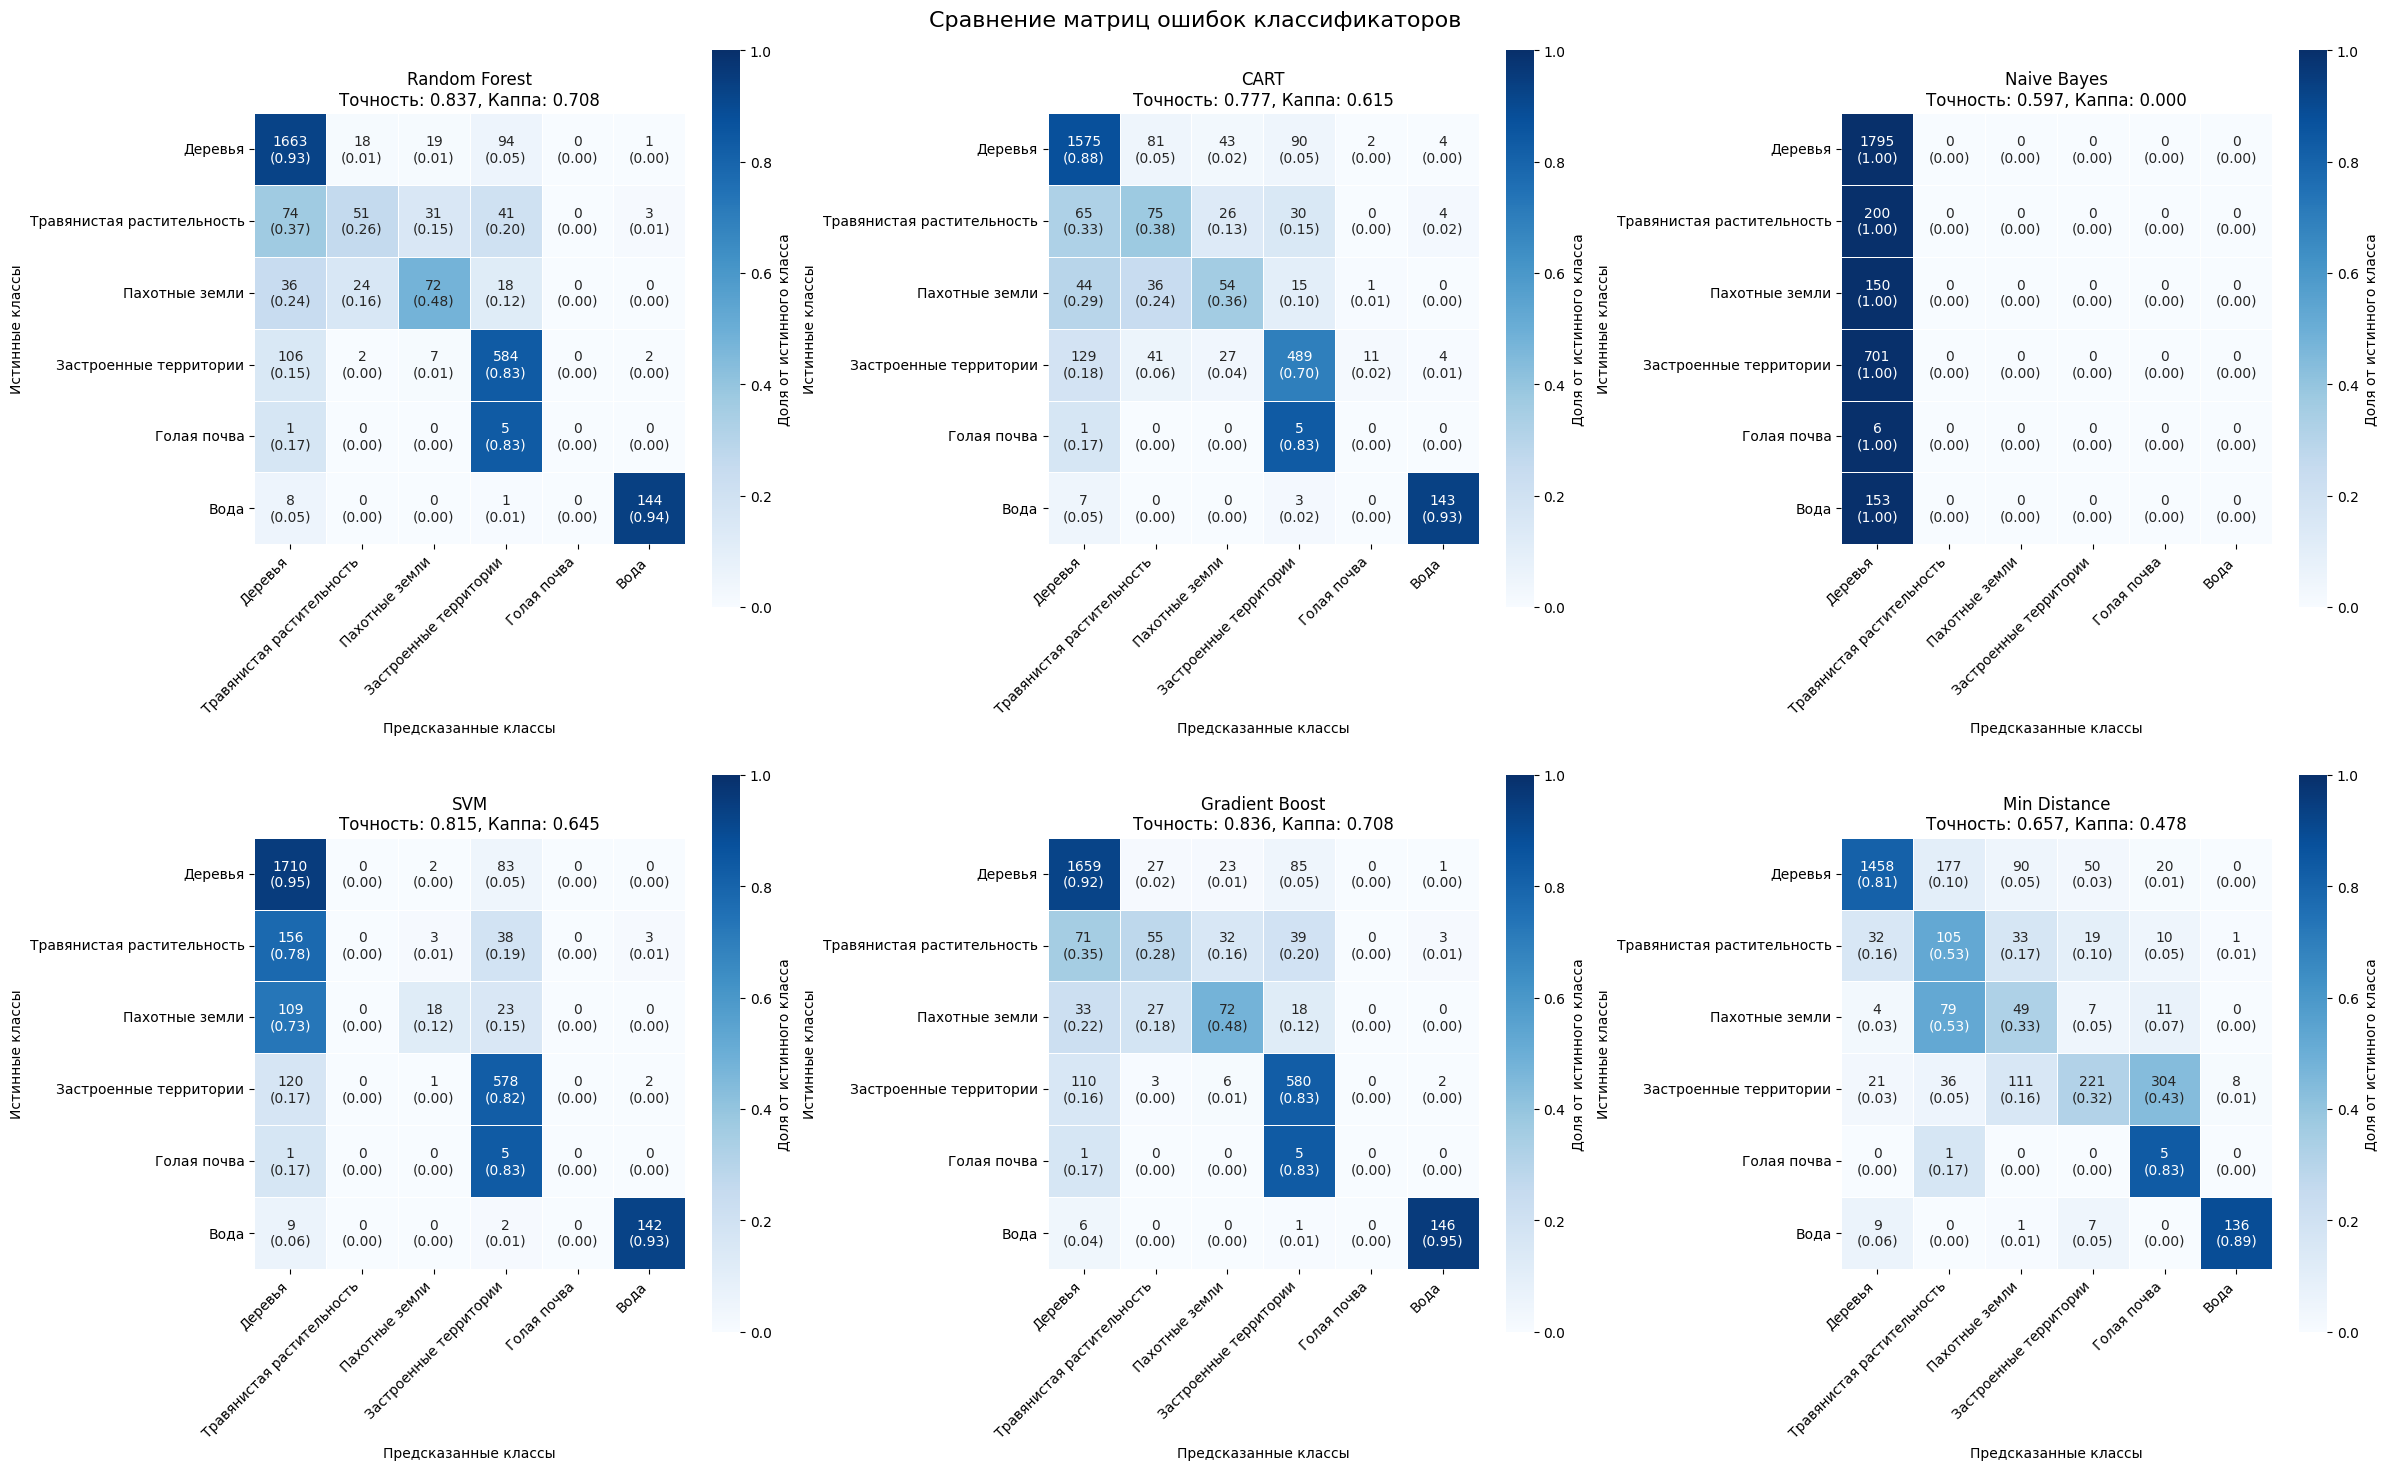

In [ ]:
# Функция для очистки матрицы ошибок от пустых классов
def clean_matrix(cm):
    """Удаляет строки и столбцы с нулевыми значениями"""
    mask = (cm.sum(axis=1) > 0) | (cm.sum(axis=0) > 0)
    return cm[mask][:, mask], np.where(mask)[0]

# Названия классов по их кодам WorldCover
code_to_name = dict(zip(CLASS_CODES, CLASS_NAMES))

# Создание визуализации матриц ошибок
fig, axes = plt.subplots(2, 3, figsize=(24, 15))
axes = axes.flatten()

for ax, (name, data) in zip(axes, results.items()):
    # Очистка матрицы от неиспользуемых классов
    cm, indices = clean_matrix(data['matrix'])

    # Нормализация матрицы по строкам (истинным классам)
    with np.errstate(divide='ignore', invalid='ignore'):
        norm = np.nan_to_num(cm / cm.sum(axis=1)[:, None])

    # Создание аннотаций с абсолютными и относительными значениями
    annot = [[f"{int(cm[i,j])}\n({norm[i,j]:.2f})"
              for j in range(len(cm))]
              for i in range(len(cm))]

    # Тепловая карта матрицы ошибок
    sns.heatmap(norm,
                annot=annot,
                fmt='',
                cmap='Blues',
                square=True,
                cbar_kws={'label': 'Доля от истинного класса'},
                ax=ax,
                linewidths=0.5,
                vmin=0,
                vmax=1)

    # Настройка подписей: строки и столбцы матрицы соответствуют кодам классов
    class_labels = [code_to_name[i] for i in indices]
    ax.set_xticklabels(class_labels, rotation=45, ha='right')
    ax.set_yticklabels(class_labels, rotation=0)
    ax.set_title(f"{name}\nТочность: {data['accuracy']:.3f}, "
                 f"Каппа: {data['kappa']:.3f}", fontsize=12)
    ax.set_xlabel('Предсказанные классы')
    ax.set_ylabel('Истинные классы')

plt.suptitle('Сравнение матриц ошибок классификаторов', fontsize=16, y=0.99)
plt.tight_layout()
plt.show()

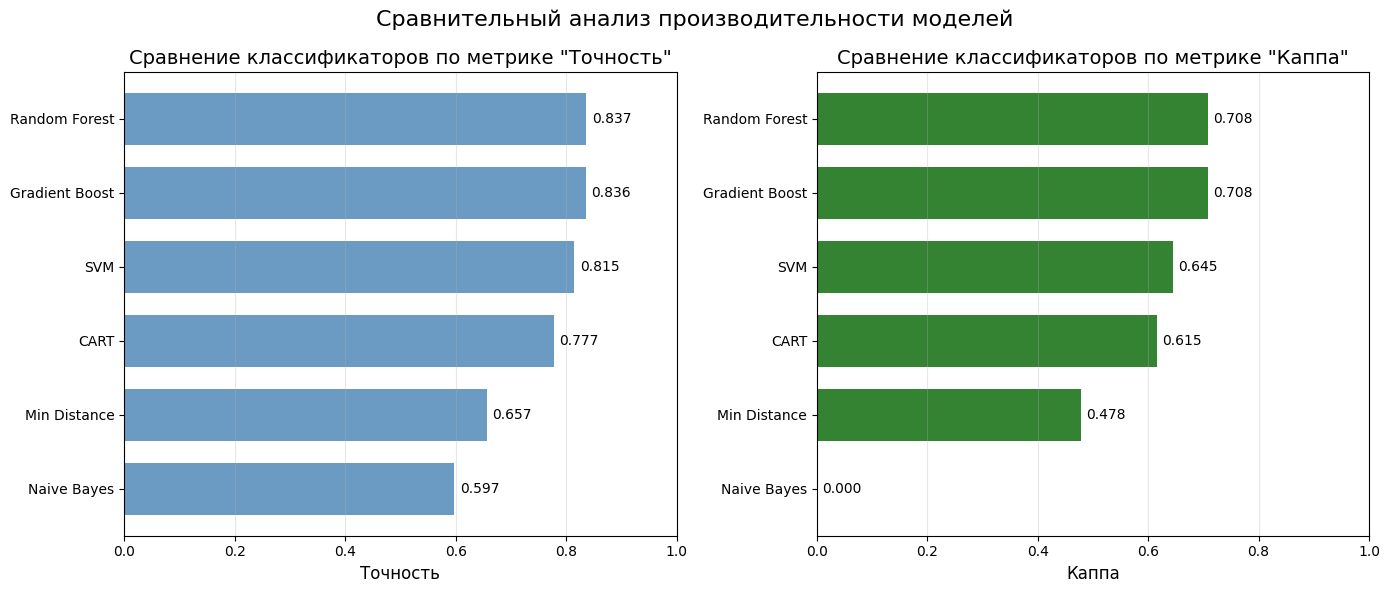

In [ ]:
# Сравнительные диаграммы метрик
metrics_df = pd.DataFrame({
    name: {'Точность': r['accuracy'], 'Каппа': r['kappa']}
    for name, r in results.items()
}).T

# График сравнения метрик
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

for ax, metric, color in [(ax1, 'Точность', 'steelblue'),
                          (ax2, 'Каппа', 'darkgreen')]:
    sorted_df = metrics_df.sort_values(metric)
    bars = ax.barh(sorted_df.index, sorted_df[metric],
                   color=color, height=0.7, alpha=0.8)

    ax.set_xlabel(metric, fontsize=12)
    ax.set_xlim(0, 1)
    ax.set_title(f'Сравнение классификаторов по метрике "{metric}"',
                 fontsize=14)
    ax.grid(axis='x', alpha=0.3)

    # Добавление значений на график
    for bar, value in zip(bars, sorted_df[metric]):
        ax.text(value + 0.01, bar.get_y() + bar.get_height()/2,
                f'{value:.3f}', va='center', fontsize=10)

plt.suptitle('Сравнительный анализ производительности моделей', fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
# Итоговая таблица результатов
print("\nСВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ:")
print("=" * 50)
metrics_df.sort_values('Точность', ascending=False).round(3)


СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ:


,Точность,Каппа
Random Forest,0.837,0.708
Gradient Boost,0.836,0.708
SVM,0.815,0.645
CART,0.777,0.615
Min Distance,0.657,0.478
Naive Bayes,0.597,0.000


In [ ]:
# Выбор лучшей модели по метрике Каппа
best_model_name = metrics_df['Каппа'].idxmax()
best_classifier = models[best_model_name]
print(f"\nЛучшая модель: {best_model_name}")


Лучшая модель: Random Forest


### **4.5. Применение обученной модели к новым данным**

In [ ]:
def classify_new_area(classifier, image, bands, new_roi=None):
    """
    Применяет обученный классификатор к новой области.

    Параметры:
        classifier: обученная модель Earth Engine
        image (ee.Image): изображение для классификации
        bands (list): список каналов для классификации
        new_roi (ee.Geometry): новая область интереса

    Возвращает:
        ee.Image: классифицированное изображение
    """
    # Использование исходной области, если новая не указана
    if new_roi is None:
        new_roi = roi

    # Обрезка изображения по области
    image_to_classify = image.clip(new_roi)

    # Применение классификатора только к нужным каналам
    classified = image_to_classify.select(bands).classify(classifier)

    return classified

In [ ]:
# Создание новой интерактивной карты для выбора области классификации
map_pred = geemap.Map(center=[55.7558, 37.6173], zoom=10)
map_pred.add_basemap('Esri.WorldTopoMap')
map_pred.add_draw_control()
map_pred

Map(center=[55.7558, 37.6173], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topri…

In [ ]:
# Получение новой области для классификации
new_roi = map_pred.user_roi

# Если область не выбрана, используем соседний район (около 12×13 км)
if new_roi is None:
    new_roi = ee.Geometry.Rectangle([38.10, 55.50, 38.30, 55.62])

In [ ]:
# Загрузка и подготовка данных для новой области
print("Загрузка данных для новой области...")
new_collection = load_sentinel2_collection(new_roi, start_date, end_date, 10)
new_composite = create_median_composite(new_collection, new_roi)
new_image = add_spectral_indices(new_composite)

# Применение лучшего классификатора
classified_image = classify_new_area(best_classifier, new_image, bands, new_roi)

Загрузка данных для новой области...


In [ ]:
# Визуализация результатов: коды классов переводятся в номера 0-10, как и для эталонной карты
map_result = geemap.Map()
map_result.add_basemap('Esri.WorldTopoMap')
map_result.centerObject(new_roi, 12)
map_result.addLayer(new_roi, {'color': 'blue'}, 'Новая область')
map_result.addLayer(new_composite, vis_params, 'RGB композит')
map_result.addLayer(to_class_index(classified_image), landcover_vis,
             f'Классификация ({best_model_name})')
map_result.add_legend(title='Классы земного покрова', legend_dict=dict(zip(CLASS_NAMES, CLASS_COLORS)))
map_result

Map(center=[55.56001016013019, 38.19999999999999], controls=(WidgetControl(options=['position', 'transparent_b…

### **4.6. Экспорт результатов классификации**

In [ ]:
# Экспорт классифицированного изображения (коды классов - целые числа)
classification_filename = f'classification_{best_model_name.lower().replace(" ", "_")}.tif'
export_georeferenced_raster(classified_image, new_roi, classification_filename, scale=10, dtype='uint8')

  0%|          |0/30 tiles [00:00<?]

Растр сохранен: classification_random_forest.tif (EPSG:32637, пиксель 10×10 м)


'classification_random_forest.tif'

Проверим экспортированную карту: выведем её с той же палитрой и посчитаем площадь каждого класса. Так как растр сохранён в проекции UTM, площадь пикселя равна 100 м², и площадь класса в гектарах — это число его пикселей, умноженное на 0,01.

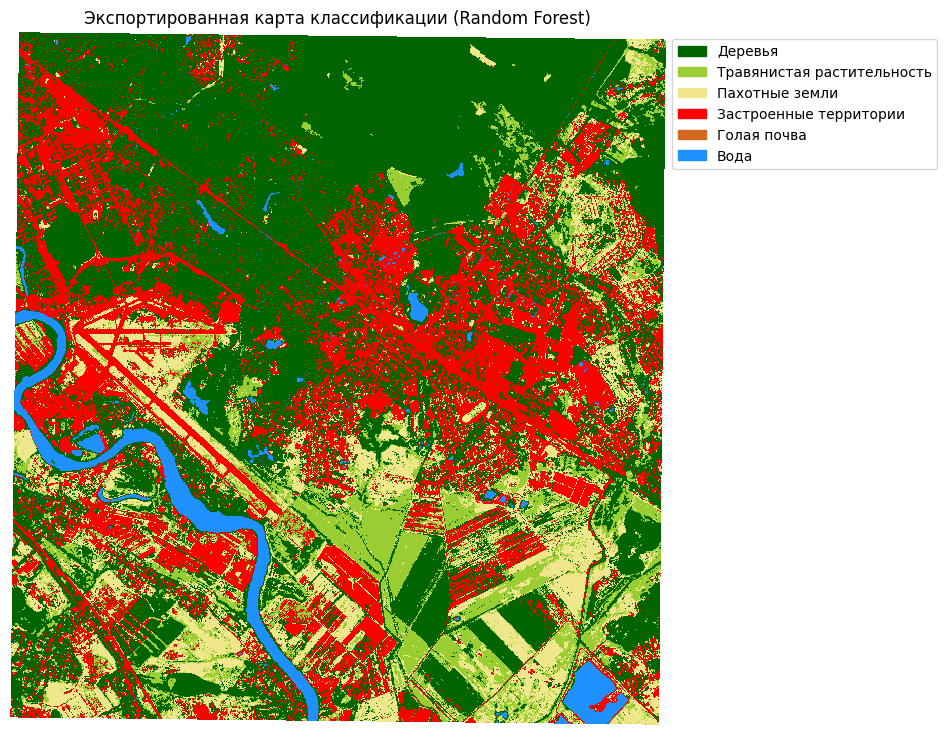

,Класс,Пикселей,"Площадь, га","Доля, %"
0,Деревья,828312,8283.1,49.1
3,Застроенные территории,415630,4156.3,24.6
2,Пахотные земли,214628,2146.3,12.7
1,Травянистая растительность,179431,1794.3,10.6
5,Вода,49186,491.9,2.9
4,Голая почва,75,0.8,0.0


In [ ]:
with rasterio.open(classification_filename) as src:
    classes = src.read(1)
    pixel_area_m2 = src.res[0] * src.res[1]
    nodata = src.nodata

# Площади классов
codes, counts = np.unique(classes[classes != nodata], return_counts=True)
areas = pd.DataFrame({
    'Класс': [code_to_name.get(c, str(c)) for c in codes],
    'Пикселей': counts,
    'Площадь, га': (counts * pixel_area_m2 / 10000).round(1),
})
areas['Доля, %'] = (100 * areas['Пикселей'] / areas['Пикселей'].sum()).round(1)

# Карта с палитрой WorldCover
cmap = plt.matplotlib.colors.ListedColormap(['#' + c for c in CLASS_COLORS])
index = np.full(classes.shape, np.nan)
for i, c in enumerate(CLASS_CODES):
    index[classes == c] = i

plt.figure(figsize=(10, 9))
plt.imshow(index, cmap=cmap, vmin=-0.5, vmax=len(CLASS_CODES) - 0.5, interpolation='nearest')
handles = [plt.Rectangle((0, 0), 1, 1, color='#' + CLASS_COLORS[CLASS_CODES.index(c)]) for c in codes]
plt.legend(handles, areas['Класс'], loc='upper left', bbox_to_anchor=(1, 1))
plt.title(f'Экспортированная карта классификации ({best_model_name})')
plt.axis('off')
plt.show()

areas.sort_values('Площадь, га', ascending=False)

Часть полей с открытой почвой модель относит к застроенным территориям. Причина видна в матрице ошибок: голой почвы на обучающем участке почти нет (в валидационной выборке — 6 пикселей, и 5 из них отнесены к застройке), поэтому модель не научилась отличать её от застройки. Это иллюстрирует, насколько результат зависит от репрезентативности обучающей выборки.

### **Выводы по разделу 4:**

1. **Random Forest и Gradient Boosting** показывают стабильно высокие результаты для классификации земного покрова благодаря устойчивости к шуму и способности работать с разнородными признаками

2. **Качество классификации** существенно зависит от:
   - Репрезентативности обучающей выборки
   - Набора используемых признаков (спектральные каналы + индексы)
   - Качества предварительной обработки данных

3. **Матрица ошибок** позволяет выявить проблемные классы и понять характер ошибок классификации

4. **Перенос обученной модели** на новые территории возможен при схожих условиях съемки и ландшафтных характеристиках

---

## **Заключение**

В рамках данного учебного блокнота были освоены основные концепции современного геопространственного анализа:

1. **Технические навыки:**
   - Работа с облачной платформой Google Earth Engine
   - Загрузка и фильтрация больших объемов спутниковых данных
   - Применение алгоритмов машинного обучения для классификации
   - Экспорт геопривязанных результатов

2. **Методологические подходы:**
   - Предварительная обработка временных серий спутниковых снимков
   - Расчет и использование спектральных индексов
   - Формирование качественных обучающих выборок
   - Валидация и сравнение моделей машинного обучения

3. **Практические результаты:**
   - Создание безоблачных композитов для анализа
   - Автоматическая классификация земного покрова
   - Оценка точности различных алгоритмов
   - Применение обученных моделей к новым территориям

### **Возможные направления применения полученных знаний**

**1. Экологический мониторинг и охрана природы:**
- Отслеживание обезлесения и деградации экосистем
- Мониторинг особо охраняемых природных территорий
- Оценка воздействия климатических изменений
- Картирование местообитаний редких видов

**2. Сельское хозяйство и продовольственная безопасность:**
- Инвентаризация сельскохозяйственных угодий
- Мониторинг состояния посевов
- Прогнозирование урожайности
- Выявление деградированных земель

**3. Управление водными ресурсами:**
- Картирование водных объектов и их изменений
- Мониторинг качества воды по оптическим свойствам
- Оценка риска наводнений
- Анализ заболоченных территорий

**4. Городское и региональное планирование:**
- Анализ роста городских территорий
- Планирование зеленой инфраструктуры
- Оценка теплового режима городов
- Мониторинг незаконного строительства